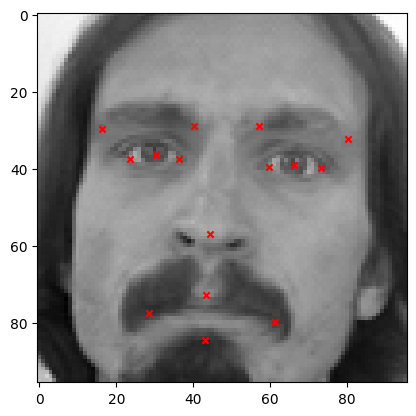

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("facial-keypoints-detection/training.csv")


# Выбираем строку (например, первую)
row = df.iloc[0]


# Парсим картинку
img = np.fromstring(row['Image'], sep=' ').reshape(96, 96)
plt.imshow(img, cmap='gray')


# Цикл по точкам: берем все колонки кроме последней (где Image)
# Данные лежат парами: x, y, x, y...
keypoints = row.drop('Image').values


for i in range(0, len(keypoints), 2):
    x = keypoints[i]
    y = keypoints[i+1]
   
    # Пропускаем визуализацию, если это NaN (если вы их не дропнули)
    if not np.isnan(x) and not np.isnan(y):
        plt.scatter(x, y, color='red', marker='x', s=20)


plt.show()


In [2]:
print("Dataset size:", df.shape)
print()
print("First cols:")
print(df.columns[:10])
print()
print("Number of skipped points:")
print(df.isna().sum())

Dataset size: (7049, 31)

First cols:
Index(['left_eye_center_x', 'left_eye_center_y', 'right_eye_center_x',
       'right_eye_center_y', 'left_eye_inner_corner_x',
       'left_eye_inner_corner_y', 'left_eye_outer_corner_x',
       'left_eye_outer_corner_y', 'right_eye_inner_corner_x',
       'right_eye_inner_corner_y'],
      dtype='object')

Number of skipped points:
left_eye_center_x              10
left_eye_center_y              10
right_eye_center_x             13
right_eye_center_y             13
left_eye_inner_corner_x      4778
left_eye_inner_corner_y      4778
left_eye_outer_corner_x      4782
left_eye_outer_corner_y      4782
right_eye_inner_corner_x     4781
right_eye_inner_corner_y     4781
right_eye_outer_corner_x     4781
right_eye_outer_corner_y     4781
left_eyebrow_inner_end_x     4779
left_eyebrow_inner_end_y     4779
left_eyebrow_outer_end_x     4824
left_eyebrow_outer_end_y     4824
right_eyebrow_inner_end_x    4779
right_eyebrow_inner_end_y    4779
right_eyebrow_o

In [3]:
# points - images detachment
# Points coords
y = df.drop(columns=["Image"]).to_numpy(dtype=np.float32)

# Images 96x96
X = np.stack(
    df["Image"].apply(
        lambda x: np.fromstring(x, sep=" ", dtype=np.float32)
    ).values
)

print("X:", X.shape)
print("y:", y.shape)

X: (7049, 9216)
y: (7049, 30)


In [4]:
X = X.reshape(-1, 1, 96, 96)

# Pixel normalize to [0, 1]
X /= 255.0

print(X.shape)

(7049, 1, 96, 96)


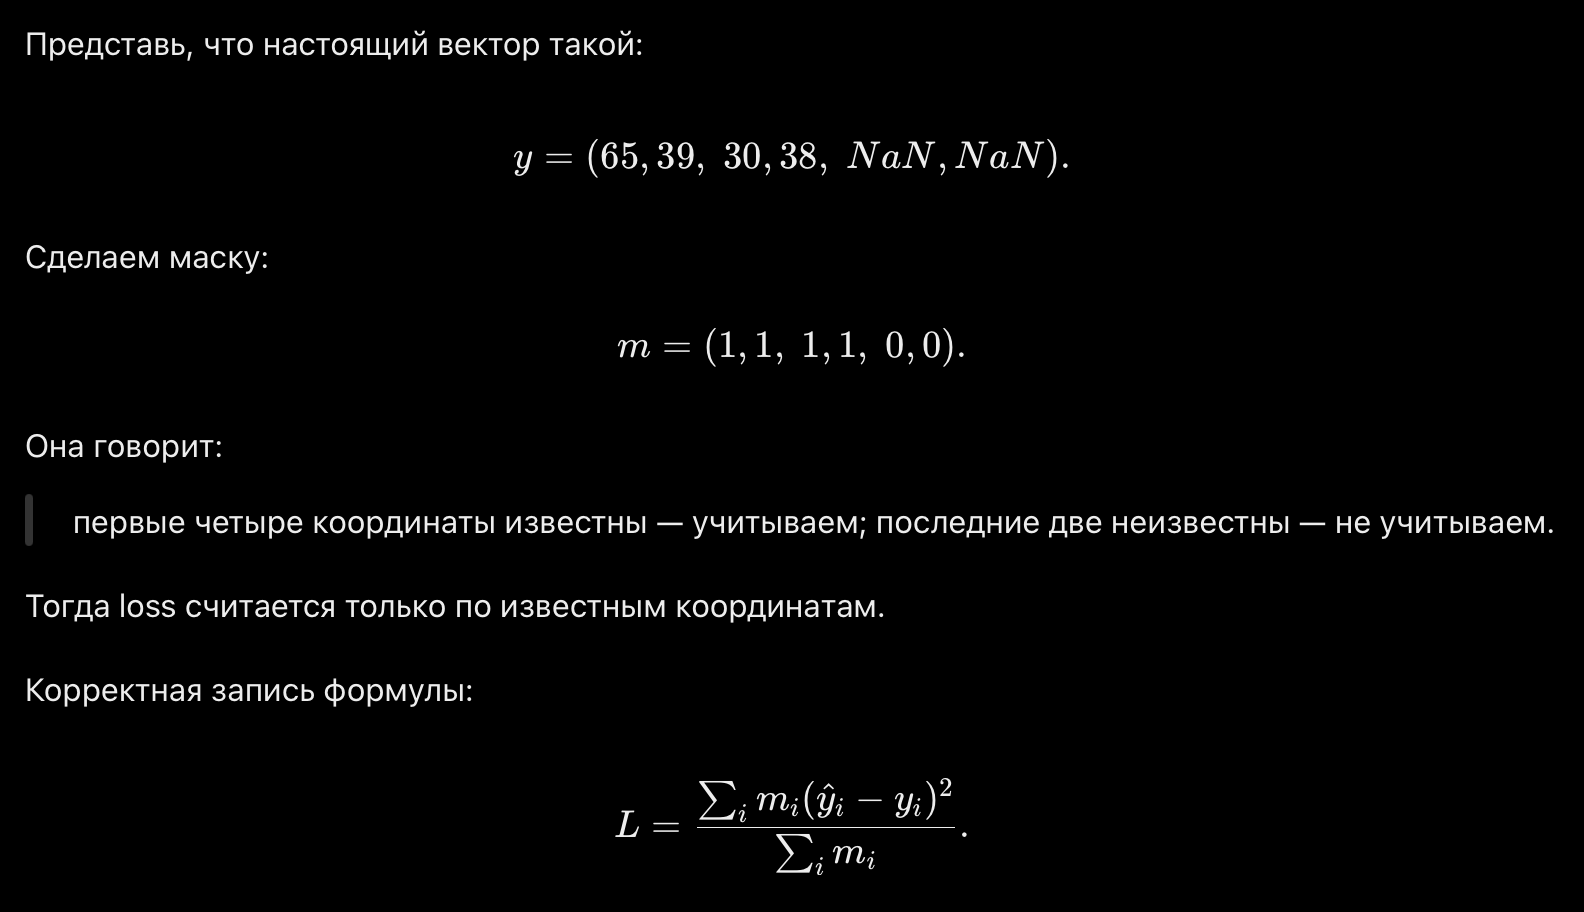

In [5]:
mask = ~np.isnan(y)

print(mask.shape)
print(mask.dtype)
print(mask[5381])

(7049, 30)
bool
[ True  True  True  True False False False False False False False False
 False False False False False False False False  True  True False False
 False False False False  True  True]


In [6]:
#NaN --> 0
y_filled = np.nan_to_num(y, nan=0.0)
print(np.isnan(y_filled).sum())

0


In [7]:
# train / val split
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val, mask_train, mask_val = train_test_split(
    X,
    y_filled,
    mask,
    test_size=0.2,
    random_state=666
)

print("Train:")
print(X_train.shape, y_train.shape, mask_train.shape)

print()

print("Validation:")
print(X_val.shape, y_val.shape, mask_val.shape)


Train:
(5639, 1, 96, 96) (5639, 30) (5639, 30)

Validation:
(1410, 1, 96, 96) (1410, 30) (1410, 30)


In [8]:
import torch
import torch.nn as nn

def masked_mse_loss(y_pred, y_true, mask):
    mask = mask.float()

    squared_error = (y_pred - y_true) ** 2
    masked_error = squared_error * mask

    return masked_error.sum() / mask.sum()

In [9]:
# ex1 augmentations
import torch
from torch.utils.data import Dataset
from torchvision import transforms


class FaceKeyPointsDataset(Dataset):
    def __init__(self, images, keypoints, masks, transform=None):
        self.images = images
        self.keypoints = keypoints
        self.masks = masks
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx].squeeze(0).copy()

        keypoints = self.keypoints[idx].reshape(-1, 2).copy()
        mask = self.masks[idx].reshape(-1, 2).copy()

        valid = mask.all(axis=1)

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                keypoints=keypoints[valid]
            )

            image = transformed["image"]

            keypoints[valid] = np.array(
                transformed["keypoints"],
                dtype=np.float32
            )

            inside = (
            (keypoints[:, 0] >= 0) & (keypoints[:, 0] < 96) &
            (keypoints[:, 1] >= 0) & (keypoints[:, 1] < 96)
            )

            # Exclude points out of bounds
            mask[valid & ~inside] = False

        image = torch.tensor(
            image,
            dtype=torch.float32
        ).unsqueeze(0)

        keypoints = torch.tensor(
            keypoints.reshape(-1),
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask.reshape(-1),
            dtype=torch.float32
        )

        return image, keypoints, mask

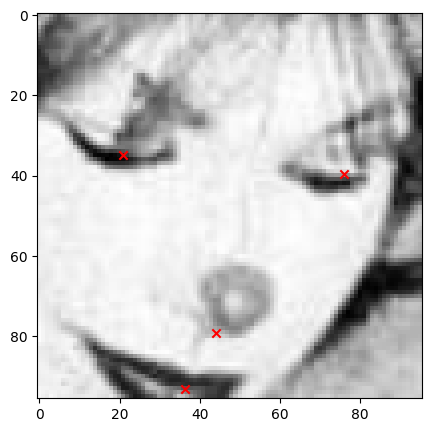

In [10]:
#no transform example
train_dataset = FaceKeyPointsDataset(
    X_train,
    y_train,
    mask_train,
    transform=None
)

image, keypoints, mask = train_dataset[90]

img = image.squeeze(0).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")

points = keypoints.numpy()

for i in range(0, len(points), 2):
    if mask[i] == 1 and mask[i + 1] == 1:
        x = points[i]
        y = points[i + 1]

        plt.scatter(x, y, color="red", marker="x")

plt.show()

In [11]:
# simple image filter transforms
import albumentations as A

train_transform = A.Compose(
    [
        A.Sharpen(
            alpha=(0.2, 0.5),
            p=0.3
        ),

        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5
        )
    ],
    keypoint_params=A.KeypointParams(
        format="xy",
        remove_invisible=False
    )
)

train_dataset = FaceKeyPointsDataset(
    X_train,
    y_train,
    mask_train,
    transform=train_transform
)

# no augmentation
val_dataset = FaceKeyPointsDataset(
    X_val,
    y_val,
    mask_val,
    transform=train_transform
)

image, keypoints, mask = train_dataset[0]

print("Image:", image.shape)
print("Keypoints:", keypoints.shape)
print("Mask:", mask.shape)

print()
print("Image type:", type(image))
print("Keypoints type:", type(keypoints))

Image: torch.Size([1, 96, 96])
Keypoints: torch.Size([30])
Mask: torch.Size([30])

Image type: <class 'torch.Tensor'>
Keypoints type: <class 'torch.Tensor'>


/Users/yanaprapirnaya/Library/Python/3.9/lib/python/site-packages/albumentations/core/composition.py:331: UserWarning: Got processor for keypoints, but no transform to process it.
  self._set_keys()


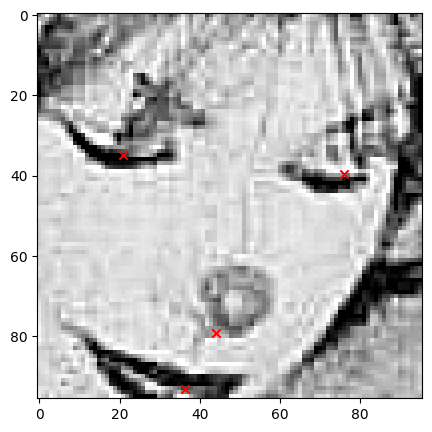

In [12]:
image, keypoints, mask = train_dataset[90]

img = image.squeeze(0).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")

points = keypoints.numpy()

for i in range(0, len(points), 2):
    if mask[i] == 1 and mask[i + 1] == 1:
        x = points[i]
        y = points[i + 1]

        plt.scatter(x, y, color="red", marker="x")

plt.show()

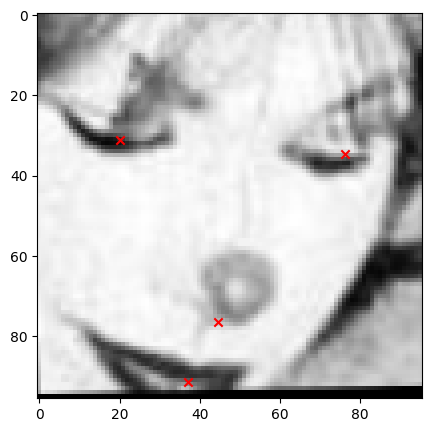

In [13]:
# scale/shift/rotate transforms
train_transform = A.Compose(
    [
        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.08, 0.08),
            rotate=(-15, 15),
            p=0.8
        ),

        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5
        ),
    ],
    keypoint_params=A.KeypointParams(
        format="xy",
        remove_invisible=False
    )
)

train_dataset = FaceKeyPointsDataset(
    X_train,
    y_train,
    mask_train,
    transform=train_transform
)

# no augmentation
val_dataset = FaceKeyPointsDataset(
    X_val,
    y_val,
    mask_val,
    transform=None
)

image, keypoints, mask = train_dataset[90]

img = image.squeeze(0).numpy()

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")

points = keypoints.numpy()

for i in range(0, len(points), 2):
    if mask[i] == 1 and mask[i + 1] == 1:
        x = points[i]
        y = points[i + 1]

        plt.scatter(x, y, color="red", marker="x")

plt.show()

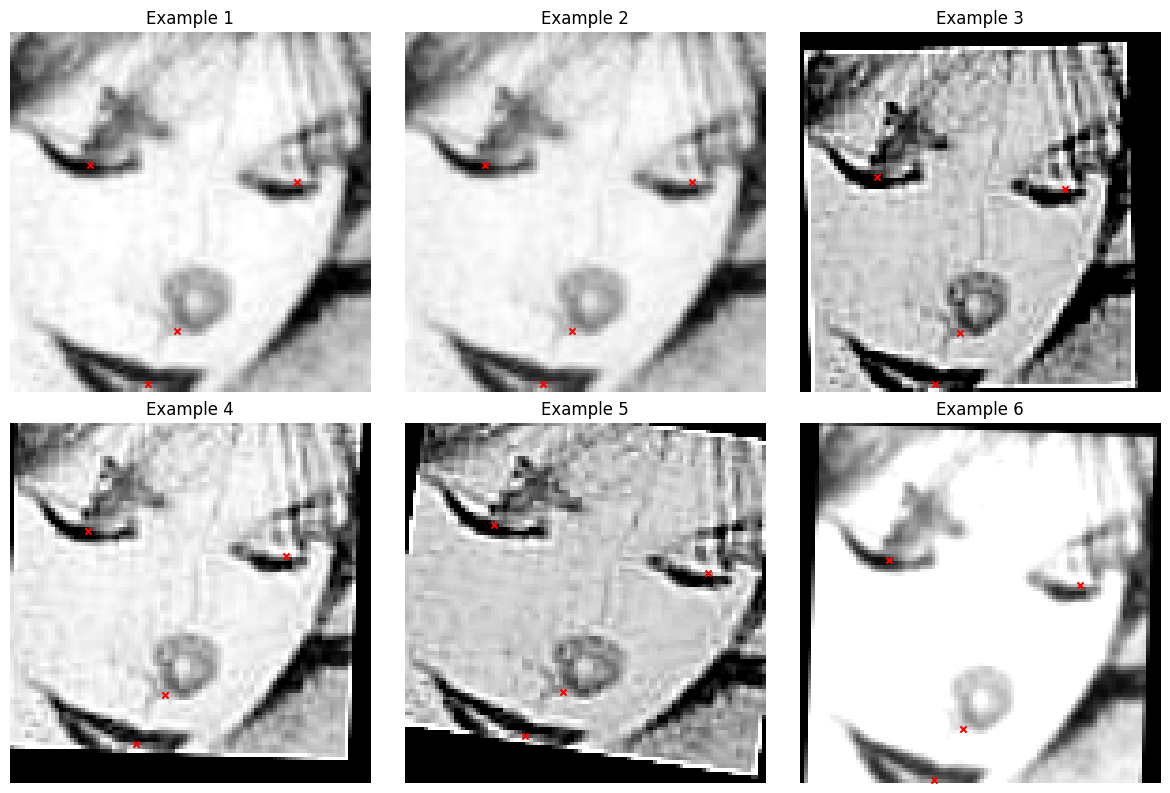

In [14]:
# ex2 - all augmentations, combined, all kinds

train_transform = A.Compose(
    [
        # scale/shift/rotate
        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.08, 0.08),
            rotate=(-15, 15),
            p=0.8
        ),

        # flip
       # A.HorizontalFlip(p=0.5),

        A.Sharpen(
            alpha=(0.2, 0.5),
            p=0.3
        ),

        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5
        )
    ],

    keypoint_params=A.KeypointParams(
        format="xy",
        remove_invisible=False
    )
)

train_dataset = FaceKeyPointsDataset(
    X_train,
    y_train,
    mask_train,
    transform=train_transform
)

val_dataset = FaceKeyPointsDataset(
    X_val,
    y_val,
    mask_val,
    transform=None
)

def show_augmented_samples(dataset, idx, n=6):
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))

    axes = axes.flatten()

    for i in range(n):
        image, keypoints, mask = dataset[idx]

        img = image.squeeze(0).numpy()
        points = keypoints.numpy().reshape(-1, 2)
        point_mask = mask.numpy().reshape(-1, 2).all(axis=1)

        axes[i].imshow(img, cmap="gray")

        valid_points = points[point_mask]

        axes[i].scatter(
            valid_points[:, 0],
            valid_points[:, 1],
            color="red",
            marker="x",
            s=20
        )

        axes[i].set_title(f"Example {i + 1}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

show_augmented_samples(
    train_dataset,
    idx=90,
    n=6
)

In [15]:
# ex 3
import torch
import torch.nn as nn
import torch.nn.functional as F


class FacialKeypointsModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)

        self.dropout = nn.Dropout(0.2)

        self.fc1 = nn.Linear(128 * 12 * 12, 512)

        self.fc2 = nn.Linear(512, 30)


    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))

        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = torch.flatten(x, 1)

        x = self.dropout(F.relu(self.fc1(x)))

        x = self.fc2(x)

        return x

In [16]:
model = FacialKeypointsModel()

dummy = torch.randn(
    4,
    1,
    96,
    96
)

output = model(dummy)

print("Input:", dummy.shape)
print("Output:", output.shape)

Input: torch.Size([4, 1, 96, 96])
Output: torch.Size([4, 30])


In [17]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

images, keypoints, masks = next(
    iter(train_loader)
)

print("Images:", images.shape)
print("Keypoints:", keypoints.shape)
print("Masks:", masks.shape)

Images: torch.Size([32, 1, 96, 96])
Keypoints: torch.Size([32, 30])
Masks: torch.Size([32, 30])


In [19]:
import lightning as L

from lightning.pytorch.loggers import MLFlowLogger
from lightning.pytorch.callbacks import ModelCheckpoint


class FacialKeypointsLightningModule(L.LightningModule):
    def __init__(self, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.model = FacialKeypointsModel()
        self.lr = lr

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        images, keypoints, masks = batch
        pred = self(images)

        loss = masked_mse_loss(pred, keypoints, masks)

        self.log("train_masked_loss", loss, on_step=False, on_epoch=True)
        self.log("train_rmse", torch.sqrt(loss), on_step=False, on_epoch=True)

        return loss

    def validation_step(self, batch, batch_idx):
        images, keypoints, masks = batch
        pred = self(images)

        loss = masked_mse_loss(pred, keypoints, masks)

        mae = (
            (torch.abs(pred - keypoints) * masks).sum()
            / masks.sum().clamp(min=1)
        )

        self.log("val_masked_loss", loss, on_step=False, on_epoch=True)
        self.log("val_rmse", torch.sqrt(loss), on_step=False, on_epoch=True)
        self.log("val_mae", mae, on_step=False, on_epoch=True)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)


class EpochLogger(L.Callback):
    def on_validation_epoch_end(self, trainer, pl_module):
        metrics = trainer.callback_metrics

        train_loss = metrics.get("train_masked_loss")
        val_loss = metrics.get("val_masked_loss")
        val_rmse = metrics.get("val_rmse")

        if train_loss is not None and val_loss is not None:
            print(
                f"Epoch {trainer.current_epoch + 1:2d}: "
                f"train_masked_loss={train_loss:.4f}, "
                f"val_masked_loss={val_loss:.4f}, "
                f"val_RMSE={val_rmse:.2f}px"
            )


mlf_logger = MLFlowLogger(
    experiment_name="facial_keypoints",
    run_name="cnn_affine",
    tracking_uri="file:./mlruns"
)

checkpoint_callback = ModelCheckpoint(
    monitor="val_masked_loss",
    mode="min",
    save_top_k=1,
    filename="best-{epoch:02d}-{val_masked_loss:.3f}"
)

lit_model = FacialKeypointsLightningModule(lr=1e-3)

trainer = L.Trainer(
    max_epochs=30,
    logger=mlf_logger,
    enable_progress_bar=False,
    enable_model_summary=False,
    callbacks=[EpochLogger(), checkpoint_callback]
)

trainer.fit(
    lit_model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores


Epoch  2: train_masked_loss=88.1523, val_masked_loss=15.7571, val_RMSE=3.89px
Epoch  3: train_masked_loss=36.3072, val_masked_loss=12.8127, val_RMSE=3.50px
Epoch  4: train_masked_loss=29.9209, val_masked_loss=18.8623, val_RMSE=4.29px
Epoch  5: train_masked_loss=28.9792, val_masked_loss=12.3699, val_RMSE=3.44px
Epoch  6: train_masked_loss=26.0941, val_masked_loss=13.9940, val_RMSE=3.66px
Epoch  7: train_masked_loss=25.3164, val_masked_loss=9.4593, val_RMSE=2.97px
Epoch  8: train_masked_loss=21.7975, val_masked_loss=15.5033, val_RMSE=3.86px
Epoch  9: train_masked_loss=21.5200, val_masked_loss=13.3844, val_RMSE=3.57px
Epoch 10: train_masked_loss=20.8902, val_masked_loss=12.4767, val_RMSE=3.46px
Epoch 11: train_masked_loss=20.9618, val_masked_loss=10.8898, val_RMSE=3.20px
Epoch 12: train_masked_loss=20.4959, val_masked_loss=14.3059, val_RMSE=3.70px
Epoch 13: train_masked_loss=19.3541, val_masked_loss=11.8707, val_RMSE=3.36px
Epoch 14: train_masked_loss=21.2799, val_masked_loss=11.9809, val

`Trainer.fit` stopped: `max_epochs=30` reached.


Epoch 30: train_masked_loss=16.3895, val_masked_loss=11.1674, val_RMSE=3.26px


In [20]:
best_model = FacialKeypointsLightningModule.load_from_checkpoint(
    checkpoint_callback.best_model_path
)

best_model.eval()

FacialKeypointsLightningModule(
  (model): FacialKeypointsModel(
    (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (dropout): Dropout(p=0.2, inplace=False)
    (fc1): Linear(in_features=18432, out_features=512, bias=True)
    (fc2): Linear(in_features=512, out_features=30, bias=True)
  )
)

In [21]:
import mlflow

mlflow.set_tracking_uri("file:./mlruns")

for exp in mlflow.search_experiments():
    print(exp.experiment_id, exp.name)

exp = mlflow.get_experiment_by_name("facial_keypoints")

runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id]
)

runs

894353751939831365 facial_keypoints
0 Default


,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.epoch,metrics.val_rmse,metrics.train_rmse,metrics.val_masked_loss,metrics.val_mae,metrics.train_masked_loss,metrics.train_loss,metrics.val_loss,params.lr,tags.mlflow.source.type,tags.mlflow.user,tags.mlflow.runName,tags.mlflow.source.name
0,c008087de1204872ab72278f244f7c31,894353751939831365,FINISHED,file:///Users/yanaprapirnaya/AI_labs_7sem/lab3...,2026-10-12 15:08:59.550000+00:00,2026-10-12 15:10:22.718000+00:00,29.0,3.262214,3.964859,11.167396,2.359481,16.125179,NaN,NaN,0.001,LOCAL,yanaprapirnaya,cnn_affine,/Users/yanaprapirnaya/Library/Python/3.9/lib/p...
1,3b562ee80fdb4a6c9564d37ba7455f46,894353751939831365,FAILED,file:///Users/yanaprapirnaya/AI_labs_7sem/lab3...,2026-10-12 15:07:59.630000+00:00,2026-10-12 15:08:02.564000+00:00,0.0,4.294168,NaN,18.938662,3.153241,NaN,NaN,NaN,0.001,LOCAL,yanaprapirnaya,cnn_affine,/Users/yanaprapirnaya/Library/Python/3.9/lib/p...
2,9afc24effa7a46a49a4666db4a691a5c,894353751939831365,FAILED,file:///Users/yanaprapirnaya/AI_labs_7sem/lab3...,2026-10-12 15:07:19.772000+00:00,2026-10-12 15:07:22.783000+00:00,0.0,4.435598,NaN,20.196825,3.287429,NaN,NaN,NaN,0.001,LOCAL,yanaprapirnaya,cnn_affine,/Users/yanaprapirnaya/Library/Python/3.9/lib/p...
3,89a9292700334a25a1d04356861e9f99,894353751939831365,FINISHED,file:///Users/yanaprapirnaya/AI_labs_7sem/lab3...,2026-10-11 21:16:21.450000+00:00,2026-10-11 21:17:44.098000+00:00,29.0,2.794232,3.989989,NaN,1.970179,NaN,16.227093,8.462097,0.001,LOCAL,yanaprapirnaya,cnn_affine,/Users/yanaprapirnaya/Library/Python/3.9/lib/p...


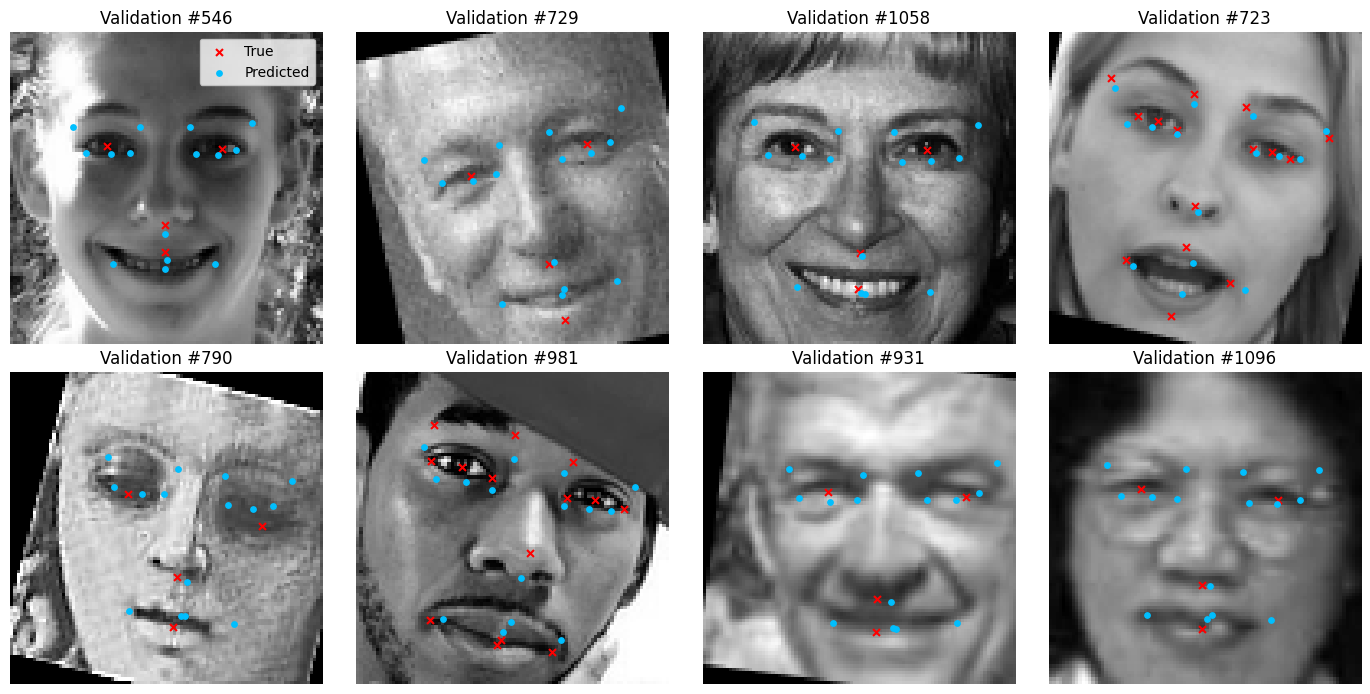

In [22]:
import random

def show_predictions(model, dataset, n=8):
    model.eval()
    device = next(model.parameters()).device

    indices = random.sample(range(len(dataset)), n)

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    with torch.no_grad():
        for ax, idx in zip(axes, indices):
            image, keypoints, mask = dataset[idx]

            pred = model(image.unsqueeze(0).to(device))
            pred = pred.squeeze(0).cpu().numpy().reshape(-1, 2)

            true = keypoints.numpy().reshape(-1, 2)
            valid = mask.numpy().reshape(-1, 2).all(axis=1)

            ax.imshow(image.squeeze(0).numpy(), cmap="gray")

            ax.scatter(
                true[valid, 0], true[valid, 1],
                c="red", marker="x", s=25, label="True"
            )

            ax.scatter(
                pred[:, 0], pred[:, 1],
                c="deepskyblue", marker="o", s=15, label="Predicted"
            )

            ax.set_title(f"Validation #{idx}")
            ax.axis("off")

    axes[0].legend()
    plt.tight_layout()
    plt.show()

val_aug_dataset = FaceKeyPointsDataset(
    X_val, y_val, mask_val,
    transform=train_transform
)

show_predictions(
    best_model,
    val_aug_dataset,
    n=8
)